In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones medias y desviaciones típicas (en semanas) se adjunta. El fin de la actividad E es un hito del proyecto (una entrega parcial) comprometido para la semana 15.

In [4]:
pregunta_1 = "1. Enumere todas las cadenas de actividades que van desde una actividad inicial hasta E (incluida) y calcule la media y la varianza de la duración de cada una.  "
pregunta_2 = "2. ¿Cuál es la fecha media del hito? ¿Qué cadena determina su varianza? Calcule la probabilidad de alcanzar el hito en la semana 15 o antes.  "
pregunta_3 = "3. Calcule la probabilidad de terminar *todo el proyecto* en la semana 28 o antes. ¿Por qué son cuestiones distintas, aunque se resuelvan igual?  "
pregunta_4 = "4. ¿Es E crítica? ¿Cambiaría la probabilidad del hito si se retrasara una actividad que no esté en ninguna cadena que llegue a E?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Enumere todas las cadenas de actividades que van desde una actividad inicial hasta E (incluida) y calcule la media y la varianza de la duración de cada una.  

2. ¿Cuál es la fecha media del hito? ¿Qué cadena determina su varianza? Calcule la probabilidad de alcanzar el hito en la semana 15 o antes.  

3. Calcule la probabilidad de terminar *todo el proyecto* en la semana 28 o antes. ¿Por qué son cuestiones distintas, aunque se resuelvan igual?  

4. ¿Es E crítica? ¿Cambiaría la probabilidad del hito si se retrasara una actividad que no esté en ninguna cadena que llegue a E?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, standard_deviation
    ('A'     , '---'      , 3       , 0.1               ),
    ('B'     , '---'      , 1       , 0.8               ),
    ('C'     , '---'      , 1       , 0.8               ),
    ('D'     , 'A,C'      , 3       , 0.4               ),
    ('E'     , 'B,D'      , 8       , 0.3               ),
    ('F'     , 'D'        , 3       , 0.6               ),
    ('G'     , 'F'        , 5       , 0.4               ),
    ('H'     , 'E,F'      , 8       , 0.6               ),
    ('I'     , 'G,H'      , 5       , 0.3               ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation
activity,,,
A,---,3,0.1
B,---,1,0.8
C,---,1,0.8
D,"A,C",3,0.4
E,"B,D",8,0.3
F,D,3,0.6
G,F,5,0.4
H,"E,F",8,0.6
I,"G,H",5,0.3


El proyecto corresponde a la organización de un congreso científico; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Definición del programa y fechas',
    'B': 'Reserva de la sede',
    'C': 'Convocatoria de comunicaciones',
    'D': 'Página web e inscripciones',
    'E': 'Contratación de ponentes invitados',
    'F': 'Revisión de los trabajos recibidos',
    'G': 'Elaboración del programa definitivo',
    'H': 'Contratación de catering y viajes',
    'I': 'Edición del libro de actas',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Definición del programa y fechas
B,Reserva de la sede
C,Convocatoria de comunicaciones
D,Página web e inscripciones
E,Contratación de ponentes invitados
F,Revisión de los trabajos recibidos
G,Elaboración del programa definitivo
H,Contratación de catering y viajes
I,Edición del libro de actas


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
X, fecha_hito = 'E', 15

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Enumere todas las cadenas de actividades que van desde una actividad inicial hasta E (incluida) y calcule la media y la varianza de la duración de cada una.  

Las cadenas que llegan al hito son los caminos del grafo de actividades (Roy) desde las iniciales hasta $X$. Cada una tiene media la suma de las medias y varianza la suma de las varianzas de sus actividades.

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

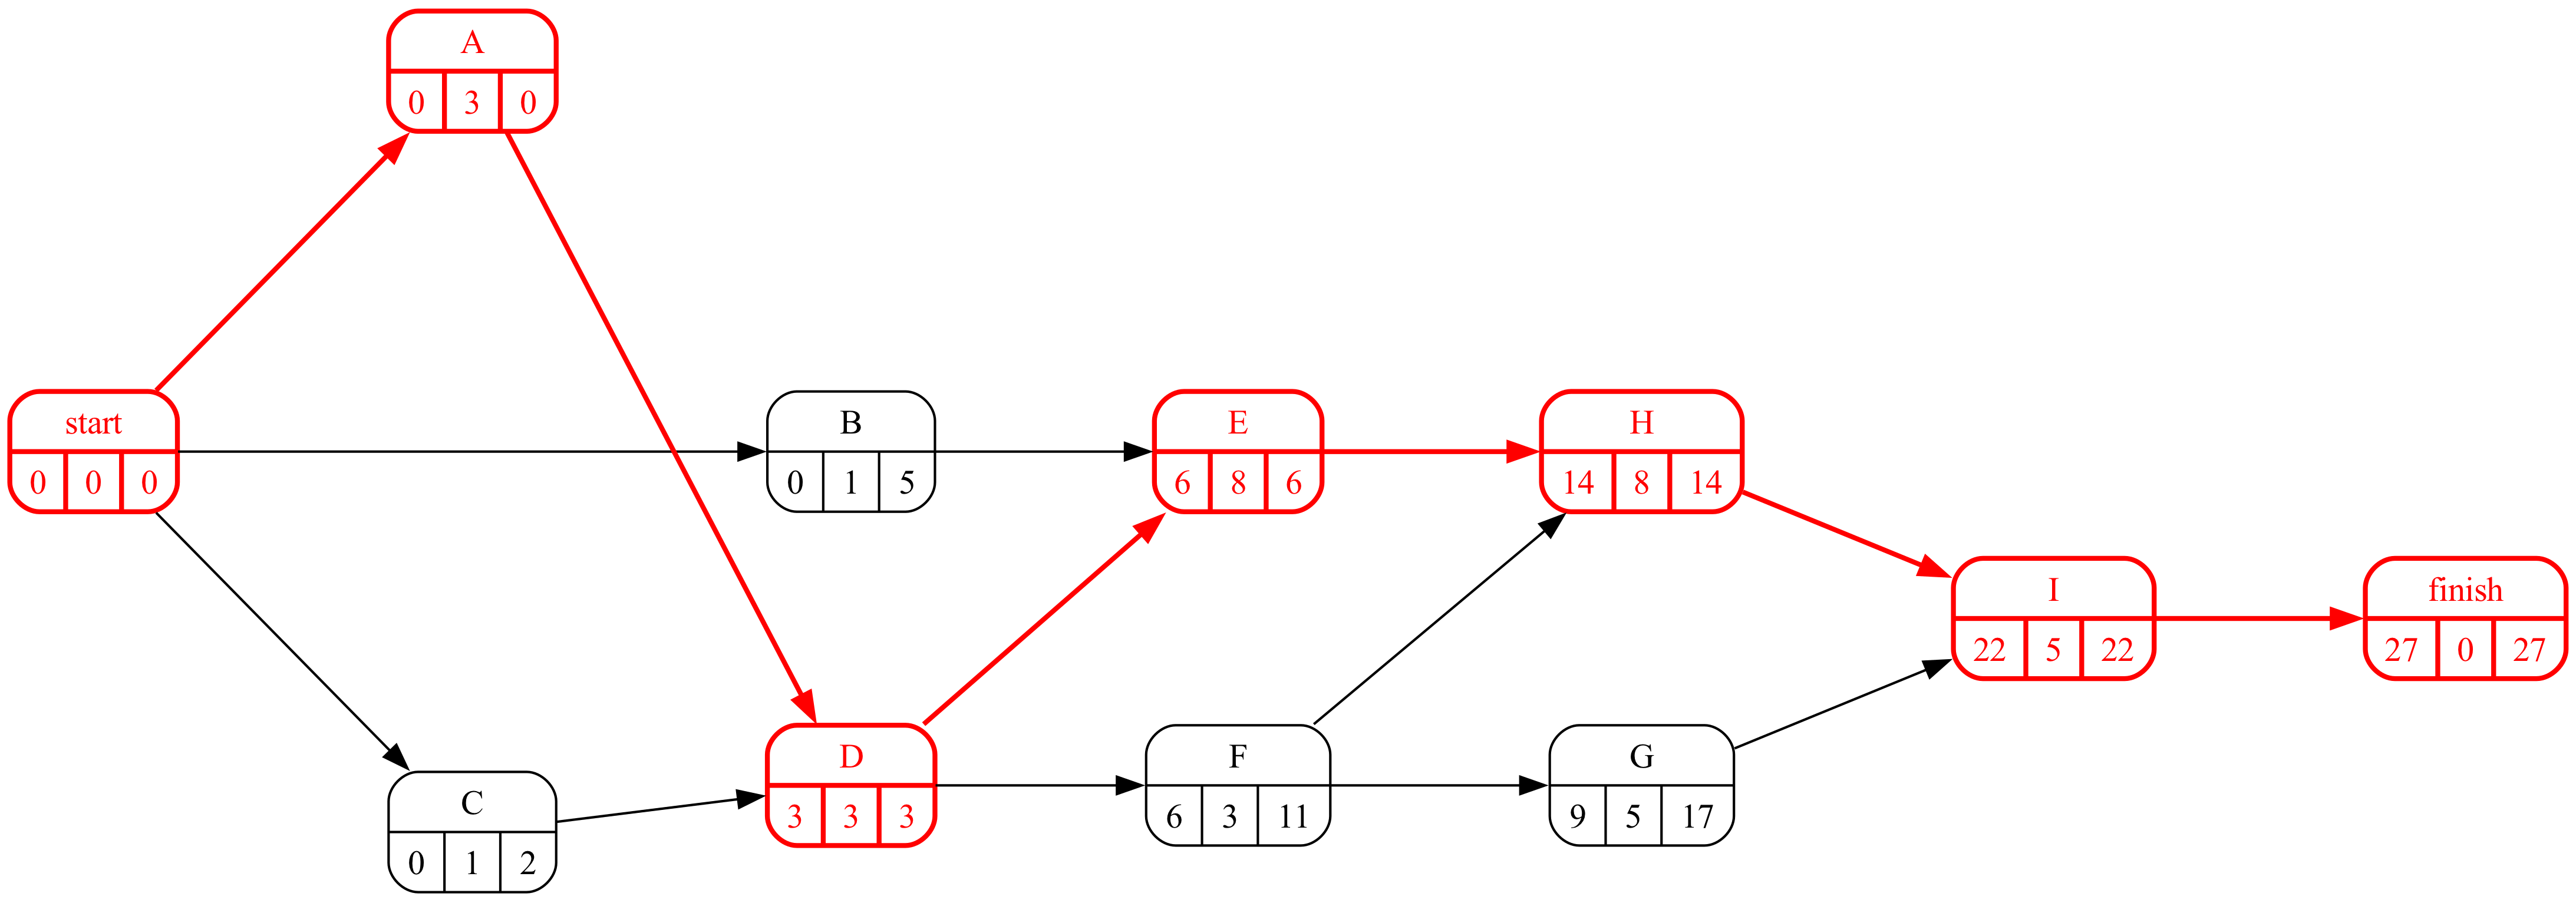

In [9]:
#| fig-cap: "Grafo Roy con el hito marcado"
#| label: fig-roy
proyecto.display_roy_pasos(datos_proyecto['duration'])

In [10]:
#| tbl-cap: "Cadenas hasta el hito"
#| label: tbl-cadenas
G = nx.DiGraph([(p, a) for a, ps in prelaciones.immediate_predecessor.items() for p in ps])
cadenas = [c for ini in sorted(prelaciones.start_activities) for c in nx.all_simple_paths(G, ini, X)]
if not cadenas:
    cadenas = [[X]]
R_hito = pd.DataFrame(0, index=[f'cadena_{i + 1}' for i in range(len(cadenas))], columns=list(datos_proyecto.index))
for i, c in enumerate(cadenas):
    R_hito.loc[f'cadena_{i + 1}', c] = 1
medias_hito = detalle_rutas(R_hito, datos_proyecto['duration'], 'media')
varianzas_hito = detalle_rutas(R_hito, datos_proyecto['variance'], 'varianza', 3)
pd.concat([medias_hito, varianzas_hito.drop(columns='actividades')], axis=1)

,actividades,media = suma,media,varianza = suma,varianza
cadena_1,A - D - E,A(3) + D(3) + E(8) = 14,14.0,A(0.010) + D(0.160) + E(0.090) = 0.260,0.26
cadena_2,B - E,B(1) + E(8) = 9,9.0,B(0.640) + E(0.090) = 0.730,0.73
cadena_3,C - D - E,C(1) + D(3) + E(8) = 12,12.0,C(0.640) + D(0.160) + E(0.090) = 0.890,0.89


## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. ¿Cuál es la fecha media del hito? ¿Qué cadena determina su varianza? Calcule la probabilidad de alcanzar el hito en la semana 15 o antes.  

In [12]:
fecha_media = float(medias_hito['media'].max())
criticas_hito = medias_hito.index[np.isclose(medias_hito['media'], fecha_media)]
varianza_hito = float(varianzas_hito.loc[criticas_hito, 'varianza'].max())
sigma_hito = float(np.sqrt(varianza_hito))
z = (fecha_hito - fecha_media) / sigma_hito
p_hito = norm.cdf(z)
Markdown(f'''La fecha media del hito es la de la cadena más larga: {fecha_media:.0f} (coincide con el fin más temprano de {X} en el calendario). Su varianza es la de esa cadena ({", ".join(criticas_hito)}; si hay empate, la de mayor varianza): {varianza_hito:.3f}, σ = {sigma_hito:.3f}. Entonces z = ({fecha_hito} − {fecha_media:.0f}) / {sigma_hito:.3f} = {z:.3f} y P(hito ≤ {fecha_hito}) = Φ({z:.3f}) = {p_hito:.4f} ({p_hito * 100:.1f} %).''')

La fecha media del hito es la de la cadena más larga: 14 (coincide con el fin más temprano de E en el calendario). Su varianza es la de esa cadena (cadena_1; si hay empate, la de mayor varianza): 0.260, σ = 0.510. Entonces z = (15 − 14) / 0.510 = 1.961 y P(hito ≤ 15) = Φ(1.961) = 0.9751 (97.5 %).

In [13]:
calendario = proyecto.calendar(datos_proyecto['duration'])
Markdown(f'Comprobación: el fin más temprano de {X} en el calendario es {int(calendario.loc[X, "fin_mas_temprano"])}.')

Comprobación: el fin más temprano de E en el calendario es 14.

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. Calcule la probabilidad de terminar *todo el proyecto* en la semana 28 o antes. ¿Por qué son cuestiones distintas, aunque se resuelvan igual?  

In [15]:
plazo = 28
duracion_media = proyecto.duration(datos_proyecto['duration'])
sigma_proyecto, varianza_rutas = proyecto.standard_deviation(durations=datos_proyecto['duration'], variances=datos_proyecto['variance'])
z_p = (plazo - duracion_media) / sigma_proyecto
p_proyecto = norm.cdf(z_p)
Markdown(f'''Para el proyecto completo: media {duracion_media}, σ = {sigma_proyecto:.3f}; z = ({plazo} − {duracion_media}) / {sigma_proyecto:.3f} = {z_p:.3f}, P(T ≤ {plazo}) = {p_proyecto:.4f}. Es la misma técnica aplicada a otro suceso: el hito depende sólo de las cadenas que llegan a {X}; el fin del proyecto, de todas las rutas completas. Una probabilidad alta del hito no garantiza una probabilidad alta del plazo, ni al revés.''')

Para el proyecto completo: media 27, σ = 0.843; z = (28 − 27) / 0.843 = 1.187, P(T ≤ 28) = 0.8823. Es la misma técnica aplicada a otro suceso: el hito depende sólo de las cadenas que llegan a E; el fin del proyecto, de todas las rutas completas. Una probabilidad alta del hito no garantiza una probabilidad alta del plazo, ni al revés.

## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. ¿Es E crítica? ¿Cambiaría la probabilidad del hito si se retrasara una actividad que no esté en ninguna cadena que llegue a E?  

In [17]:
es_critica = int(calendario.loc[X, 'H_total']) == 0
antecesoras = nx.ancestors(G, X) | {X}
ajenas = sorted(set(datos_proyecto.index) - antecesoras)
Markdown(f'''{X} {"es" if es_critica else "no es"} crítica (holgura total {int(calendario.loc[X, "H_total"])}). La probabilidad del hito sólo depende de las actividades de sus cadenas ({", ".join(sorted(antecesoras))}); un retraso en {", ".join(ajenas)} no la altera, aunque sí pueda alterar la del proyecto.''')

E es crítica (holgura total 0). La probabilidad del hito sólo depende de las actividades de sus cadenas (A, B, C, D, E); un retraso en F, G, H, I no la altera, aunque sí pueda alterar la del proyecto.